# Small Programs, Explicit Evidence

## Neuro-symbolic grid synthesis with bounded invariance verification

Technical artifact paper with disclosed AI assistance. The public ARC training corpus is an evaluation resource, not the private ARC Prize 2026 competition test set.

## Abstract

Program synthesis offers inspectable hypotheses for abstract grid transformations, but fitting examples is not the same as generalizing to unseen grids. This artifact combines a real learned proposal ranking network, a finite transformation DSL, example-consistency verification and explicitly scoped color-renaming checks. A NumPy multilayer perceptron learns to rank sixteen operators from independently generated synthetic example sets. The synthesizer enumerates one- and two-operation programs and learns a consistent palette binding from each task's provided examples. Geometric candidates receive Z3 checks of their pinned training-grid predictions. Structural candidates receive exact concrete checks. Color conjugacy is checked symbolically on a bounded grid for geometric programs and through labelled metamorphic trials for structural programs. Evaluation includes all 400 tasks in a pinned public ARC-AGI training split and 240 generated held-out tasks. Both search modes solve 20 of 400 public tasks exactly. The neural mode solves 234 of 240 generated tasks, versus 233 for uniform ordering. The discrepancy between easy in-grammar synthesis and broad ARC reasoning is the central empirical finding. No private-test accuracy, state-of-the-art performance or general-intelligence claim is made.

## 1. Introduction

An ARC task provides a few input/output demonstrations and asks for exact output grids on new inputs. The representation is compact, but the required abstraction can involve object roles, counting, connectivity, symmetry, conditional rules or a task-specific compositional concept. A generic geometric DSL covers only a small part of that space.

The research question here is not whether a sixteen-operator library solves ARC generally. It is whether a small solver can separate learned proposal priorities, exact example constraints and invariance evidence in a reproducible way. Reporting failures on the entire public corpus is important because high accuracy on generated tasks from the same operator vocabulary can otherwise create an inflated impression of capability.

The artifact supplies a real solver, an actual trained ranker, a pinned licensed dataset and per-task measurements. It also makes certificate scope a first-class result. A concrete match, a bounded symbolic result and a held-out correct prediction are recorded as different kinds of evidence.

## 2. Data and evaluation separation

The public dataset is the complete training directory of Francois Chollet's ARC-AGI repository at commit `399030444e0ab0cc8b4e199870fb20b863846f34`. It contains 400 tasks and 416 within-task test pairs. A download script consolidates the JSON files without altering grid values and preserves the Apache 2.0 license.

The corpus digest is checked before evaluation. All task identifiers are evaluated in sorted order. No subset is selected because it is easy or solved. The result is public-training-corpus accuracy, not the private evaluation accuracy of any current ARC competition.

For a given task, only its provided training example pairs enter feature extraction, ranking, palette fitting and synthesis. Test outputs are consulted solely in the evaluation harness after a program is selected. A program that fits every provided demonstration can still produce an incorrect held-out output, and such a task is scored incorrect.

The synthetic held-out set contains fifteen tasks per operator, for 240 tasks. Each has three demonstration pairs and one new input. Model training, model validation and solver evaluation use separate random-number streams. These streams do not establish a formal guarantee that every finite grid is unique across datasets. The vocabulary is deliberately shared, so this is in-grammar generalization rather than a test of discovering unseen abstractions.

## 3. Program language

The DSL contains identity, three rotations, horizontal and vertical reflections, transpose, two-times nearest-neighbor enlargement, whole-grid tiling, horizontal and vertical tiling, nonzero bounding-box crop, downward gravity, largest-component retention, hole filling and a rightward shift.

A program is an ordered tuple of one or two operators followed by a learned color map. Candidate outputs exceeding the ARC grid dimension limit are rejected. Grids must be rectangular, nonempty, at most thirty cells per axis and contain integer colors from zero through nine.

Palette fitting requires each observed source color to map consistently to one target color across all demonstrations after the geometric or structural transform. Multiple colors may map to the same target. An unseen source color defaults to itself on a held-out input. That default is explicit and can cause generalization failure; it is not a learned semantic guarantee.

Several operations assume zero is background. Largest-component ties are resolved by raster encounter order. Hole-fill color ties use first appearance rather than numeric color order to preserve the intended zero-preserving color-renaming behavior. These choices are part of the DSL contract, not claims about every ARC task.

## 4. Learned proposal ranking

The ranker is an actual one-hidden-layer MLP trained with cross-entropy gradient descent in NumPy. It uses 32 hidden units, tanh activation, sixteen output classes and 180 training epochs. Training comprises sixty synthetic tasks per operator, or 960 labelled example sets. A separate 192-set validation stream measures top-one operator classification.

Features summarize grid dimensions, dimension ratios, nonzero fractions, color cardinalities and per-operator shape/equality evidence on the provided demonstrations. Including operator-specific comparisons makes this a small discriminative proposal ranker, not a general perceptual reasoning model.

The same DSL and palette fitting are available in both ablations. Uniform mode uses a fixed operator order. Neural mode prioritizes operators according to the learned probabilities and orders depth-two compositions by their combined score. It does not remove low-ranked candidates or read held-out answers.

The reported candidate count refers to candidates submitted to palette fitting and verification. It does not include the single-operator evaluations performed during neural feature extraction. Thus, a smaller fitted-candidate count is not by itself a total-work or speedup result. Measured search time includes feature extraction and ranking overhead.

The model weights are saved to an NPZ artifact and hashed. No model weights are copied from a hosted system, and no external inference endpoint participates.

## 5. Verification layers

### 5.1 Exact training consistency

Every selected candidate must reproduce every provided demonstration exactly. Concrete tuple equality is checked first. For geometric programs, symbolic input cells are then pinned to each actual training grid and the candidate's output expressions are constrained to disagree with the expected output. Unsatisfiability confirms that no disagreement exists under those pinned inputs.

This is a finite input-specific certificate. It does not prove that the program is the intended task rule or that an unseen output is correct. The implementation reports `z3_unsat` for these candidates. Structural operators have input-dependent branches and use exact concrete checks reported as `exact_concrete`, rather than pretending that the same symbolic encoding covers them.

### 5.2 Color conjugacy

Color names should often behave as labels rather than numeric magnitudes. Let P be a permutation fixing zero. The relevant property is conjugacy of the program under relabelling, with its learned palette map transformed by P. The checked equation is

```text
P(F_M(x)) = F_(P M P^-1)(P(x))
```

For geometric programs, the symbolic check quantifies over all color assignments to a three-by-four input grid and searches for a counterexample. Its result applies to that grid shape and the selected permutation. It is not advertised as a proof over arbitrary shapes, arbitrary rotations or every permutation.

For structural programs, twenty generated grids are tested under one seeded zero-preserving permutation. These are metamorphic observations, not universal SMT proofs. The raw ledger records the method, scope and status separately.

A correct invariance result can coexist with an incorrect task prediction. Many wrong programs are consistently wrong under color relabelling. Invariance is therefore supporting evidence about implementation behavior, not an oracle for the task's latent concept.

## 6. Search and runtime protocol

The search grammar has sixteen depth-one candidates and 256 depth-two compositions. Candidate generation has a nominal one-second admission deadline. The deadline is checked before each candidate, while individual Z3 checks have their own timeout. Consequently it is a soft search limit rather than a hard operating-system execution cap.

For every task and ablation the ledger records program steps, learned palette, certificate status, fitted-candidate count, exact test-pair outcomes and measured search milliseconds. It separately records color-conjugacy results.

Per-task search runtime includes ranking and training-consistency verification. It excludes the one-time ranker training and the subsequently reported invariance checks. Training time and validation accuracy are metadata. Median, p95 and aggregate search time are generated from the actual task measurements.

The solver's use of exact integer grid colors avoids image similarity thresholds. A task is correct only if every test output grid is exactly equal. Dimensions, color values and all cells must match.

## 7. Empirical results

On the public corpus, both uniform and neural modes solve twenty of four hundred tasks, an exact task accuracy of five percent. Twenty of the 416 test pairs are correct. Twenty-one tasks have a program fitting all demonstrations, so training consistency is not sufficient for held-out success.

On the generated set, uniform ordering solves 233 of 240 tasks and neural ordering solves 234. All generated tasks admit a training-consistent candidate. The remaining errors demonstrate ambiguity, palette defaults or prioritization among candidates that fit the same demonstrations.

Neural ranking substantially changes the number of candidates reached on these in-vocabulary synthetic tasks, but this does not establish a broad runtime advantage. Its feature extraction, learned scoring and certificate checks cost time. The actual latency table must be consulted rather than inferring speed from candidate counts.

The public-corpus result is the important corrective. A high generated-task score does not translate into broad ARC performance. The implemented vocabulary lacks many object relations, counting transformations, conditional branches, scale inference and richer abstractions. Learning an operator order cannot recover a concept absent from the language.

The one-task synthetic difference is not presented as statistically significant. Single-seed measurements and a shared synthetic vocabulary are inadequate for a strong generalization claim. The artifact provides the raw results needed for multi-seed extensions.

## 8. Error analysis and limitations

Unsolved public tasks generally have no training-consistent program in this grammar. A fitted but incorrect program is a different failure mode and should not be counted as a search failure. The ledger distinguishes these outcomes.

A full neuro-symbolic ARC system would require a richer object representation, parameterized operations, task-conditioned branching and an uncertainty policy for ambiguous hypotheses. It might also learn new reusable abstractions rather than rank a fixed list. Those capabilities are not implemented here.

Symbolic training checks pin inputs and cannot certify unseen answers. Bounded color conjugacy covers a particular shape and permutation. Structural metamorphic checks sample only twenty grids. None of these results is a complete proof of general task correctness.

Features contain hand-engineered operator comparisons. They are legitimate within-task evidence but mean the ranker is not learning arbitrary grid semantics from pixels. The model is small and trained only on generated transformations. No language model or image encoder is used.

The artifact was evaluated on public training tasks whose examples and test outputs are openly available. Even though the harness withholds test outputs from synthesis, public data is not equivalent to a competition's unreleased test set. No prize-track score or ranking is inferred.

## 9. Reproducibility and conclusion

The pinned corpus, license, source digest, saved neural weights, raw task ledger, CSV tables and notebook are included. Reproduction is offline after dependency installation because the public corpus is bundled. Exact prediction counts should reproduce with the specified seed and implementation; timings remain hardware-dependent.

This small solver demonstrates how learned search order and several types of verification evidence can coexist without being conflated. The low public-corpus accuracy is reported openly. The useful contribution is an executable baseline with honest certificate scope and a clear separation between fitting, invariance and generalization.

## References

1. Francois Chollet. On the Measure of Intelligence, 2019. [arXiv 1911.01547](https://arxiv.org/abs/1911.01547).
2. Francois Chollet. [ARC-AGI dataset repository](https://github.com/fchollet/ARC-AGI).
3. Matej Balog, Alexander Gaunt, Marc Brockschmidt, Sebastian Nowozin and Daniel Tarlow. DeepCoder, learning to write programs, 2017. [arXiv 1611.01989](https://arxiv.org/abs/1611.01989).
4. Z3 project. [Source and documentation](https://github.com/Z3Prover/z3).
5. ARC Prize. [ARC Prize 2026 Paper Track page](https://www.kaggle.com/competitions/arc-prize-2026-paper-track). Its page title does not establish private-test results or eligibility.

## Executable reproduction

The next cell reruns the actual benchmark. Only the bundled public data and synthetic fixtures are used. Install the pinned requirements first. Hardware-dependent timings may change. Unavailable GPU backends are not relabelled as CPU results.

## Recomputed empirical results

| split | mode | tasks | solved | exact_task_accuracy | test_pairs | exact_pair_accuracy | training_fits | z3_training_certificates | invariance_checks_passed | mean_candidates | median_ms | p95_ms | total_ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| generated_heldout | uniform | 240 | 233 | 0.970833 | 240 | 0.970833 | 240 | 196 | 240 | 7.691667 | 19.762645 | 75.772198 | 5815.719210 |
| generated_heldout | neural | 240 | 234 | 0.975000 | 240 | 0.975000 | 240 | 179 | 240 | 1.000000 | 20.768688 | 78.045892 | 5838.684215 |
| arc_public_training | uniform | 400 | 20 | 0.050000 | 416 | 0.048077 | 21 | 14 | 21 | 260.192500 | 18.043063 | 90.685054 | 12027.101292 |
| arc_public_training | neural | 400 | 20 | 0.050000 | 416 | 0.048077 | 21 | 9 | 21 | 259.225000 | 18.462313 | 95.583456 | 12611.315790 |


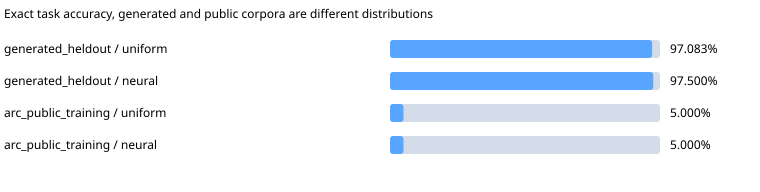

{
  "environment": {
    "system": "Darwin",
    "architecture": "arm64",
    "python": "3.13.18",
    "dependencies": {
      "numpy": "2.3.4",
      "z3-solver": "4.15.3.0",
      "cryptography": "46.0.3"
    }
  },
  "metadata": {
    "seed": 2026,
    "grammar": [
      "identity",
      "rot90",
      "rot180",
      "rot270",
      "flip_h",
      "flip_v",
      "transpose",
      "upscale2",
      "tile2",
      "tile_h",
      "tile_v",
      "crop_nonzero",
      "gravity_down",
      "keep_largest",
      "fill_holes",
      "shift_right"
    ],
    "max_depth": 2,
    "search_timeout_seconds": 1.0,
    "source_commit": "399030444e0ab0cc8b4e199870fb20b863846f34",
    "dataset_sha256": "7577f9fa12311153f5c2f2f2e2d39b370e4fabbfad64ce813ef040533e139735",
    "dataset_scope": "all 400 public ARC-AGI training tasks, never private competition evaluation",
    "neural_training_ms": 224.442583,
    "neural_training_samples": 960,
    "neural_validation_samples": 192,
    "neural_val

In [1]:
import json, os, subprocess, sys, tempfile
from pathlib import Path
from IPython.display import display, Markdown, SVG

# Run from the bundle root or the paper directory. No personal path is embedded.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "research_common.py").is_file()), None)
if ROOT is None and Path("/kaggle/input").is_dir():
    mounted = list(Path("/kaggle/input").glob("*/research_common.py"))
    mounted += list(Path("/kaggle/input").glob("*/kaggle_submissions/research_common.py"))
    if len(mounted) == 1:
        ROOT = mounted[0].parent
if ROOT is None:
    raise RuntimeError("Open this notebook within the complete research bundle")
sys.path.insert(0, str(ROOT))
from research_common import markdown_table
from publication_builder import comparison_svg

env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1"}
with tempfile.TemporaryDirectory(prefix="research-reproduction-") as temporary:
    output = Path(temporary)
    child = subprocess.run(
        [sys.executable, str(ROOT / 'arc-prize-2026-paper-track' / 'arc_verifier.py'), "--output", str(output)],
        text=True, capture_output=True, env=env, timeout=600,
    )
    if child.returncode:
        raise RuntimeError("Benchmark failed; inspect the local command output")
    report = json.loads((output / "results.json").read_text())

assert report["schema_version"] == 1
assert report["summary"]
display(Markdown("## Recomputed empirical results\n\n" + markdown_table(report["summary"])))
if "acoustic" in report["metadata"]:
    display(Markdown("## Recomputed acoustic results\n\n" + markdown_table(report["metadata"]["acoustic"])))
display(SVG(comparison_svg('arc-prize-2026-paper-track', report)))
print(json.dumps({"environment": report["environment"], "metadata": report["metadata"]}, indent=2))
